In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

import matplotlib.pyplot as plt
%matplotlib inline
from sklearn import datasets
from sklearn.model_selection import train_test_split
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import math

plt.rcParams['font.sans-serif']=[u'SimHei']
plt.rcParams['axes.unicode_minus']=False

In [3]:
#f(x) = w1*x**2 + w2*x + b
X = np.linspace(0,10,num=50).reshape(-1,1)
X = np.concatenate([X**2,X],axis=1)
X.shape



(50, 2)

Text(0.5, 1.0, 'w1:7,w2:3,b:-3')

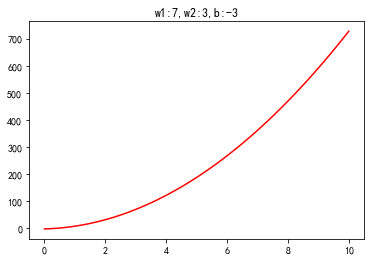

In [14]:
w = np.random.randint(1,10,size=2)
b = np.random.randint(-5,5,size=1)

y = X.dot(w) + b

plt.plot(X[:,1],y,c='red')
plt.title('w1:%d,w2:%d,b:%d'%(w[0],w[1],b[0]))


In [15]:
#使用sklearn进行预测
lr = LinearRegression()
lr.fit(X,y)
print(lr.coef_,lr.intercept_)


[7. 3.] -3.0000000000000853


In [ ]:
###自己手写的线性回归，拟合多元方程

In [18]:
def gradient_descent(X,y,lr,epoch,w,b):
    
    batch = len(X)
    for i in range(epoch):
        d_loss = 0
        dw = [0 for _ in range(len(w))]
        db = 0
        for j in range(batch):
            y_ = 0
            for n in range(len(w)):
                y_ +=X[j][n] * w[n]
            y_ += b
            
            d_loss = -(y[j] - y_)
            for n in range(len(w)):
                dw[n] += X[j][n] * d_loss/float(batch)
            db += d_loss /float(batch)
            
    
        for n in range(len(w)):
            w[n] -= dw[n]*lr[n]
        b -= db*lr[0]
        
    return w,b

In [22]:
lr=[0.0001,0.001]
w = np.random.randn(2)
b = np.random.randn(1)[0]
w_,b_ = gradient_descent(X,y,lr,500,w,b)


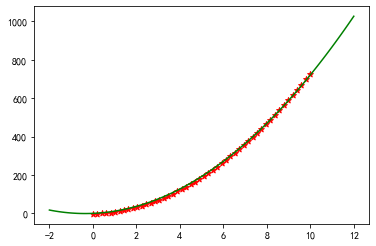

In [24]:
plt.scatter(X[:,1],y,marker='*',c='red')
x = np.linspace(-2,12,100)
f = lambda x:w_[0]*x**2 + w_[1] * x + b_
plt.plot(x,f(x),color='green')